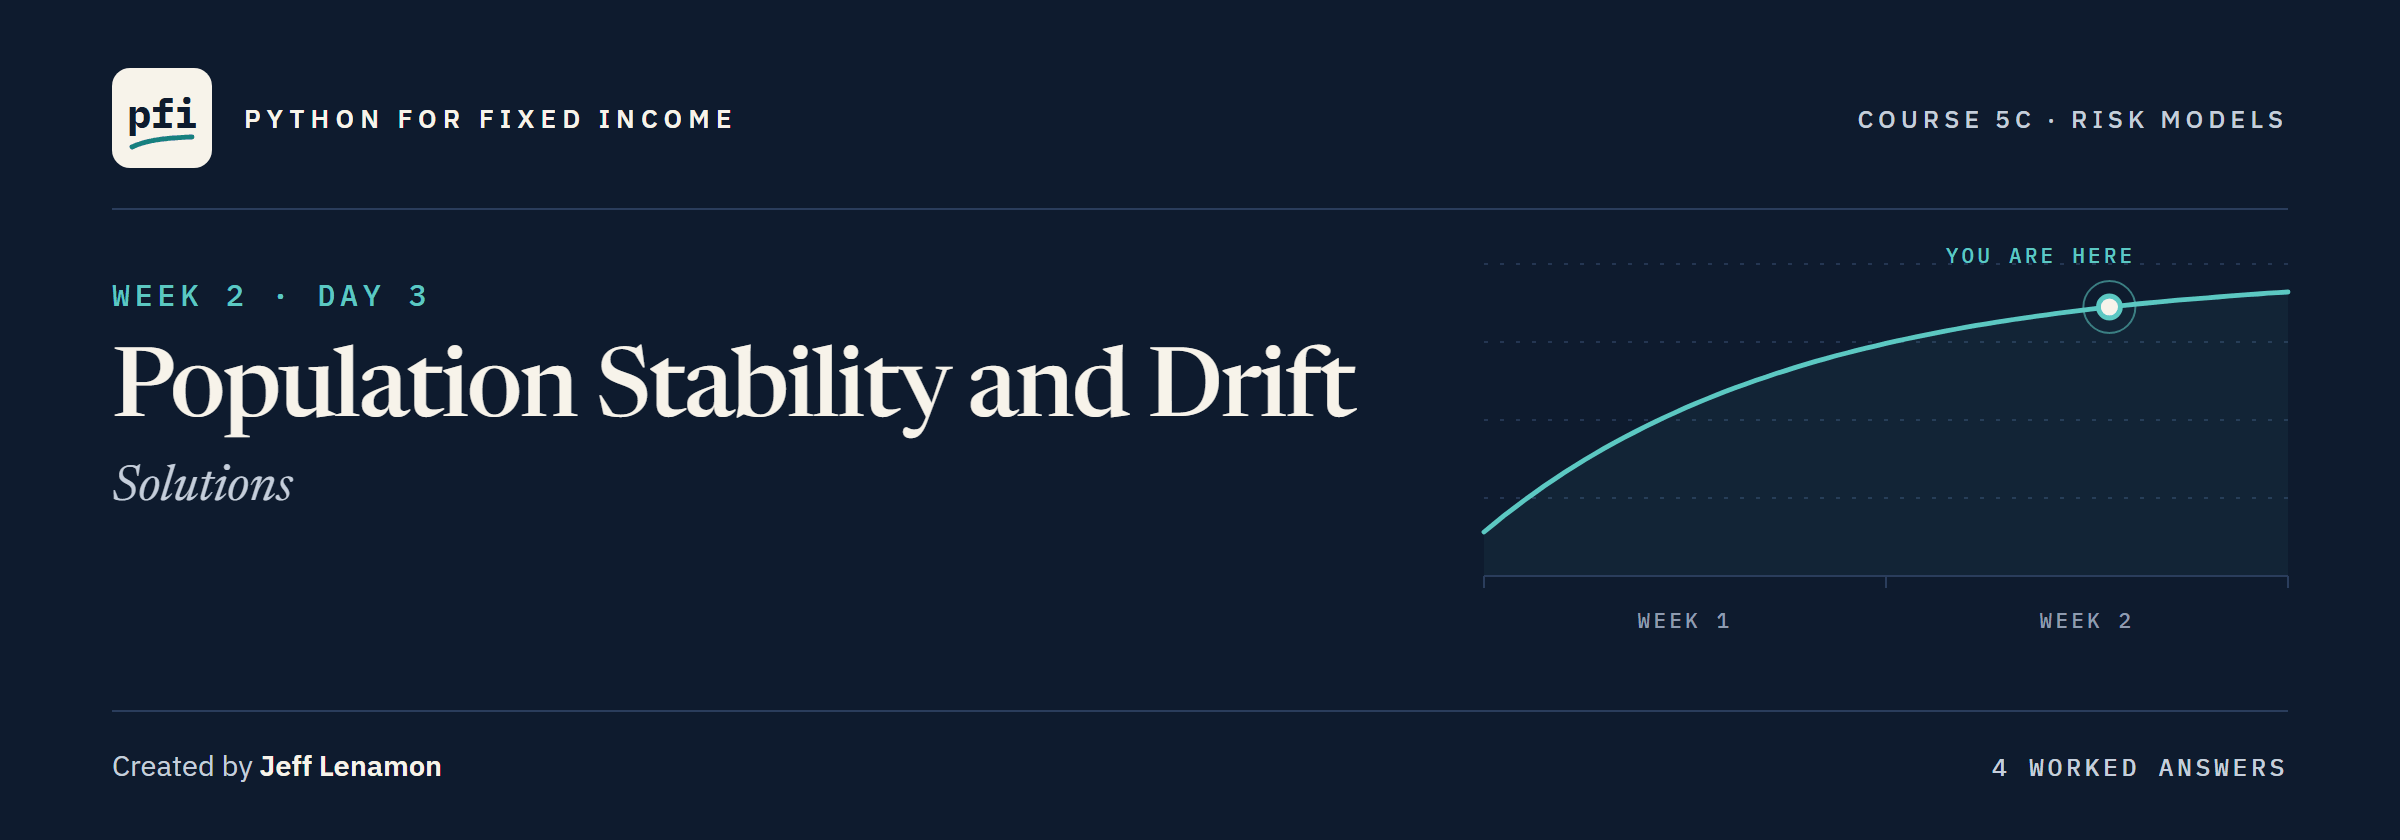

# Population Stability and Drift: Solutions

Week 2, Day 3. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day3/08_population_stability_and_drift_solutions.ipynb)

# Problem Statement

## Business Context

A risk team watches whether the inputs its models read have moved away from the ones the models were built on.
Two populations are checked today, both inside the development years.
The first is the 10 Yr yield and its daily change in 2019 to 2022, against 2015 to 2018.
The second is the cohort's firms entering in study years 11 to 14, against those entering in 1 to 10, on the inputs Day 5's hazard model reads.
The cohort's generator tilts the firms entering from study year 11 toward lower ratings and higher leverage (`DATA.md`); today checks what a drift measure finds.
A drift measure says how far a mix moved from its reference, never where it goes next.

## Objectives

Fix a reference sample and its quantile bins before reading the compared sample.
Compute a PSI by hand and as a function, and handle an empty bin with a floor.
Turn the number of bins and the way they are cut.
Read PSI window by window against one reference.
Measure each input's drift on the cohort's entering firms, and see where in the distribution it sits.
Set PSI beside the KS test and Jensen-Shannon on the same samples.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day: `date` and `10 Yr`, the par yield in percent (`2 Yr` in the exercises).

`course5c_cohort.csv`, one row per firm per study year (the columns used today):

1. `firm_id`: the firm, an invented id
2. `study_year`: 1 to 20, never a calendar year
3. `years_since_entry`: 1 in the firm's entry year
4. `rating_score`: 1 (AAA) to 18 (CCC)
5. `leverage`: debt to EBITDA, times
6. `coverage`: EBITDA to interest, times

`sector` waits for the exercises; `default`, `exit` and `rating` are not read today.

Made here: `level` (percent), `change` (bp, whole numbers), the `reference_` and `compared_` samples, `level_edges`, and `entrants` (each firm's entry row).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data; math's log takes part in one cell that fails on purpose
import math
import numpy as np
import pandas as pd

# the two-sample KS test and the Jensen-Shannon distance
from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Curve's Development Years

In [3]:
# the Treasury par yields in percent, one row per trading day
curve = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")

# Course 5B's cut: the development years end on 2022-12-30; the held-out rows are counted and never read
CUT = "2022-12-30"
print("Development rows:", len(curve.loc[:CUT]), "| held-out rows:", len(curve) - len(curve.loc[:CUT]))

Development rows: 2001 | held-out rows: 939


In [4]:
# the 10 Yr's level in percent, and its daily change in bp, rounded to whole bp
level = curve.loc[:CUT, "10 Yr"]
change = (level.diff() * 100).round(0).iloc[1:]
print(len(level), "levels and", len(change), "changes, from", change.index[0].date(), "to", change.index[-1].date())
print(f"Change: sd {change.std():.2f} bp a day, as on Day 2")

2001 levels and 2000 changes, from 2015-01-05 to 2022-12-30
Change: sd 5.03 bp a day, as on Day 2


The file's yields carry two decimals, so a day's change is a whole number of bp.

The subtraction leaves binary tails (Course 3's notebook 06) that would put a 2 bp day on either side of a 2 bp bin edge; `.round(0)` clears them.

## Fixing the Reference and Its Edges First

The **reference sample** is the population a model was built on; the **compared sample** is the one checked against it.
Here 2015 to 2018 is the reference and 2019 to 2022 the compared.
The reference's nine deciles cut it into ten equal shares: they are the **bin edges**.

In [5]:
# the reference years and their deciles: the nine edges every PSI of the level will count in
reference_level = level.loc[:"2018-12-31"]
level_edges = np.quantile(reference_level, np.arange(1, 10) / 10)
print(len(reference_level), "reference days | edges (percent):", level_edges.round(2))

# the daily change's reference and edges, the same way
reference_change = change.loc[:"2018-12-31"]
print(len(reference_change), "reference changes | edges (bp):", np.quantile(reference_change, np.arange(1, 10) / 10))

1000 reference days | edges (percent): [1.74 1.89 2.09 2.2  2.28 2.36 2.45 2.82 2.94]
999 reference changes | edges (bp): [-5. -3. -2. -1.  0.  1.  2.  4.  5.]


In [6]:
# only now the compared years, 2019 to 2022
compared_level = level.loc["2019-01-01":]
compared_change = change.loc["2019-01-01":]
print(len(compared_level), "compared levels and", len(compared_change), "compared changes")

1001 compared levels and 1001 compared changes


**The reference and its edges are fixed before one compared day is read.**

## Reading the Cohort

In [7]:
# the synthetic cohort, and Day 3's split: development study years 1 to 14; the later years are counted and left alone
cohort = pd.read_csv(DATA + "course5c_cohort.csv")
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END]
print("Development firm-years:", len(development), "| firms:", development["firm_id"].nunique(), "| held-out firm-years:", len(cohort) - len(development))

Development firm-years: 18503 | firms: 3504 | held-out firm-years: 11112


In [8]:
# each firm's entry row, and the reference firms: those entering in study years 1 to 10
entrants = development[development["years_since_entry"] == 1]
reference_firms = entrants[entrants["study_year"] <= 10]
print("Entering firms:", len(entrants), "| one row a firm:", entrants["firm_id"].is_unique, "| reference firms:", len(reference_firms))

Entering firms: 3504 | one row a firm: True | reference firms: 2508


An entry row holds the firm's inputs in its first year, before any of its own history could move them.

# Data Overview

## The 10 Yr Over Eight Years

In [9]:
# the reference's range, and the compared days below and above it
low, high = reference_level.min(), reference_level.max()
print(f"2015 to 2018: {low:.2f} to {high:.2f} percent | 2019 to 2022: {compared_level.min():.2f} to {compared_level.max():.2f}")
print(f"Compared days below the reference's lowest: {100 * (compared_level < low).mean():.1f} percent | above its highest: {100 * (compared_level > high).mean():.1f}")

2015 to 2018: 1.37 to 3.24 percent | 2019 to 2022: 0.52 to 4.25
Compared days below the reference's lowest: 29.8 percent | above its highest: 8.7


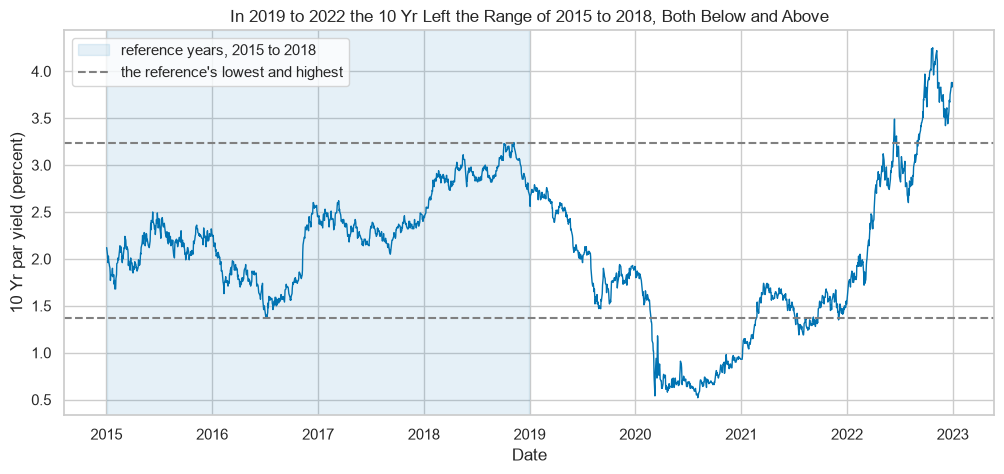

In [10]:
# the 10 Yr level, the reference years shaded and their range dashed
plt.figure(figsize=(12, 5))
plt.plot(level.index, level, linewidth=1)
plt.axvspan(level.index[0], pd.Timestamp("2018-12-31"), color="C0", alpha=0.1, label="reference years, 2015 to 2018")
plt.axhline(low, color="gray", linestyle="--", label="the reference's lowest and highest")
plt.axhline(high, color="gray", linestyle="--")
plt.xlabel("Date")
plt.ylabel("10 Yr par yield (percent)")
plt.title("In 2019 to 2022 the 10 Yr Left the Range of 2015 to 2018, Both Below and Above")
plt.legend(loc="upper left")
plt.show()

Over a third of the compared days sat outside every value the reference held.

The file does not record why the 10 Yr moved.

## The Daily Change

In [11]:
# all 2,000 daily changes in bp (Day 2's development moves, whole bp)
change.describe().round(2)

count    2000.00
mean        0.09
std         5.03
min       -30.00
25%        -3.00
50%         0.00
75%         3.00
max        29.00
Name: 10 Yr, dtype: float64

The middle half of the days ran from -3 to +3 bp.

## Entering Firms by Study Year

In [12]:
# blanks in the three inputs, and any firm entering twice
print("Blanks:", entrants[["rating_score", "leverage", "coverage"]].isna().sum().sum(), "| firms entering twice:", entrants["firm_id"].duplicated().sum())

Blanks: 0 | firms entering twice: 0


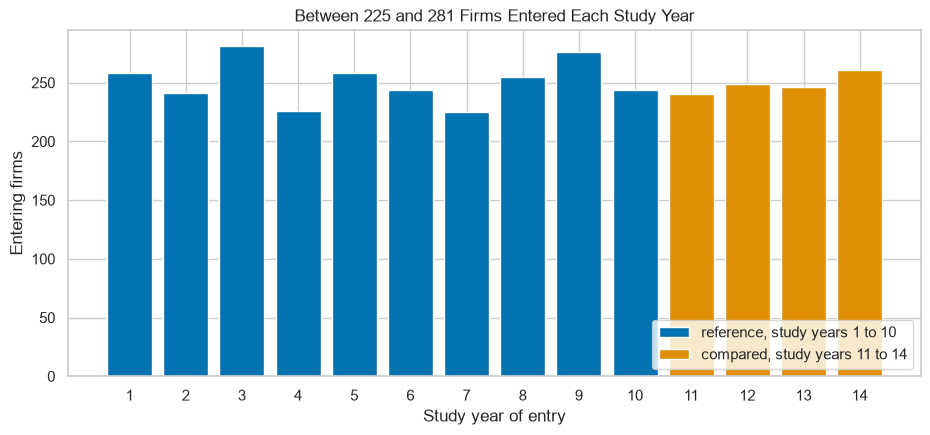

In [13]:
# entering firms by study year: the reference years in one colour, the compared years in another
by_entry = entrants["study_year"].value_counts().sort_index()
plt.figure(figsize=(11, 4.5))
plt.bar(by_entry.index[:10], by_entry.iloc[:10], label="reference, study years 1 to 10")
plt.bar(by_entry.index[10:], by_entry.iloc[10:], label="compared, study years 11 to 14")
plt.xticks(by_entry.index)
plt.xlabel("Study year of entry")
plt.ylabel("Entering firms")
plt.title(f"Between {by_entry.min()} and {by_entry.max()} Firms Entered Each Study Year")
plt.legend(loc="lower right")
plt.show()

**Two clean populations: the curve's edges are fixed, and the cohort's are fixed before its compared firms are read.**

# PSI by Hand

## The Recipe

The **population stability index (PSI)** compares two mixes on fixed bins.
Each bin's **term** is (compared share - reference share) x ln(compared share / reference share); PSI is the sum of the terms.

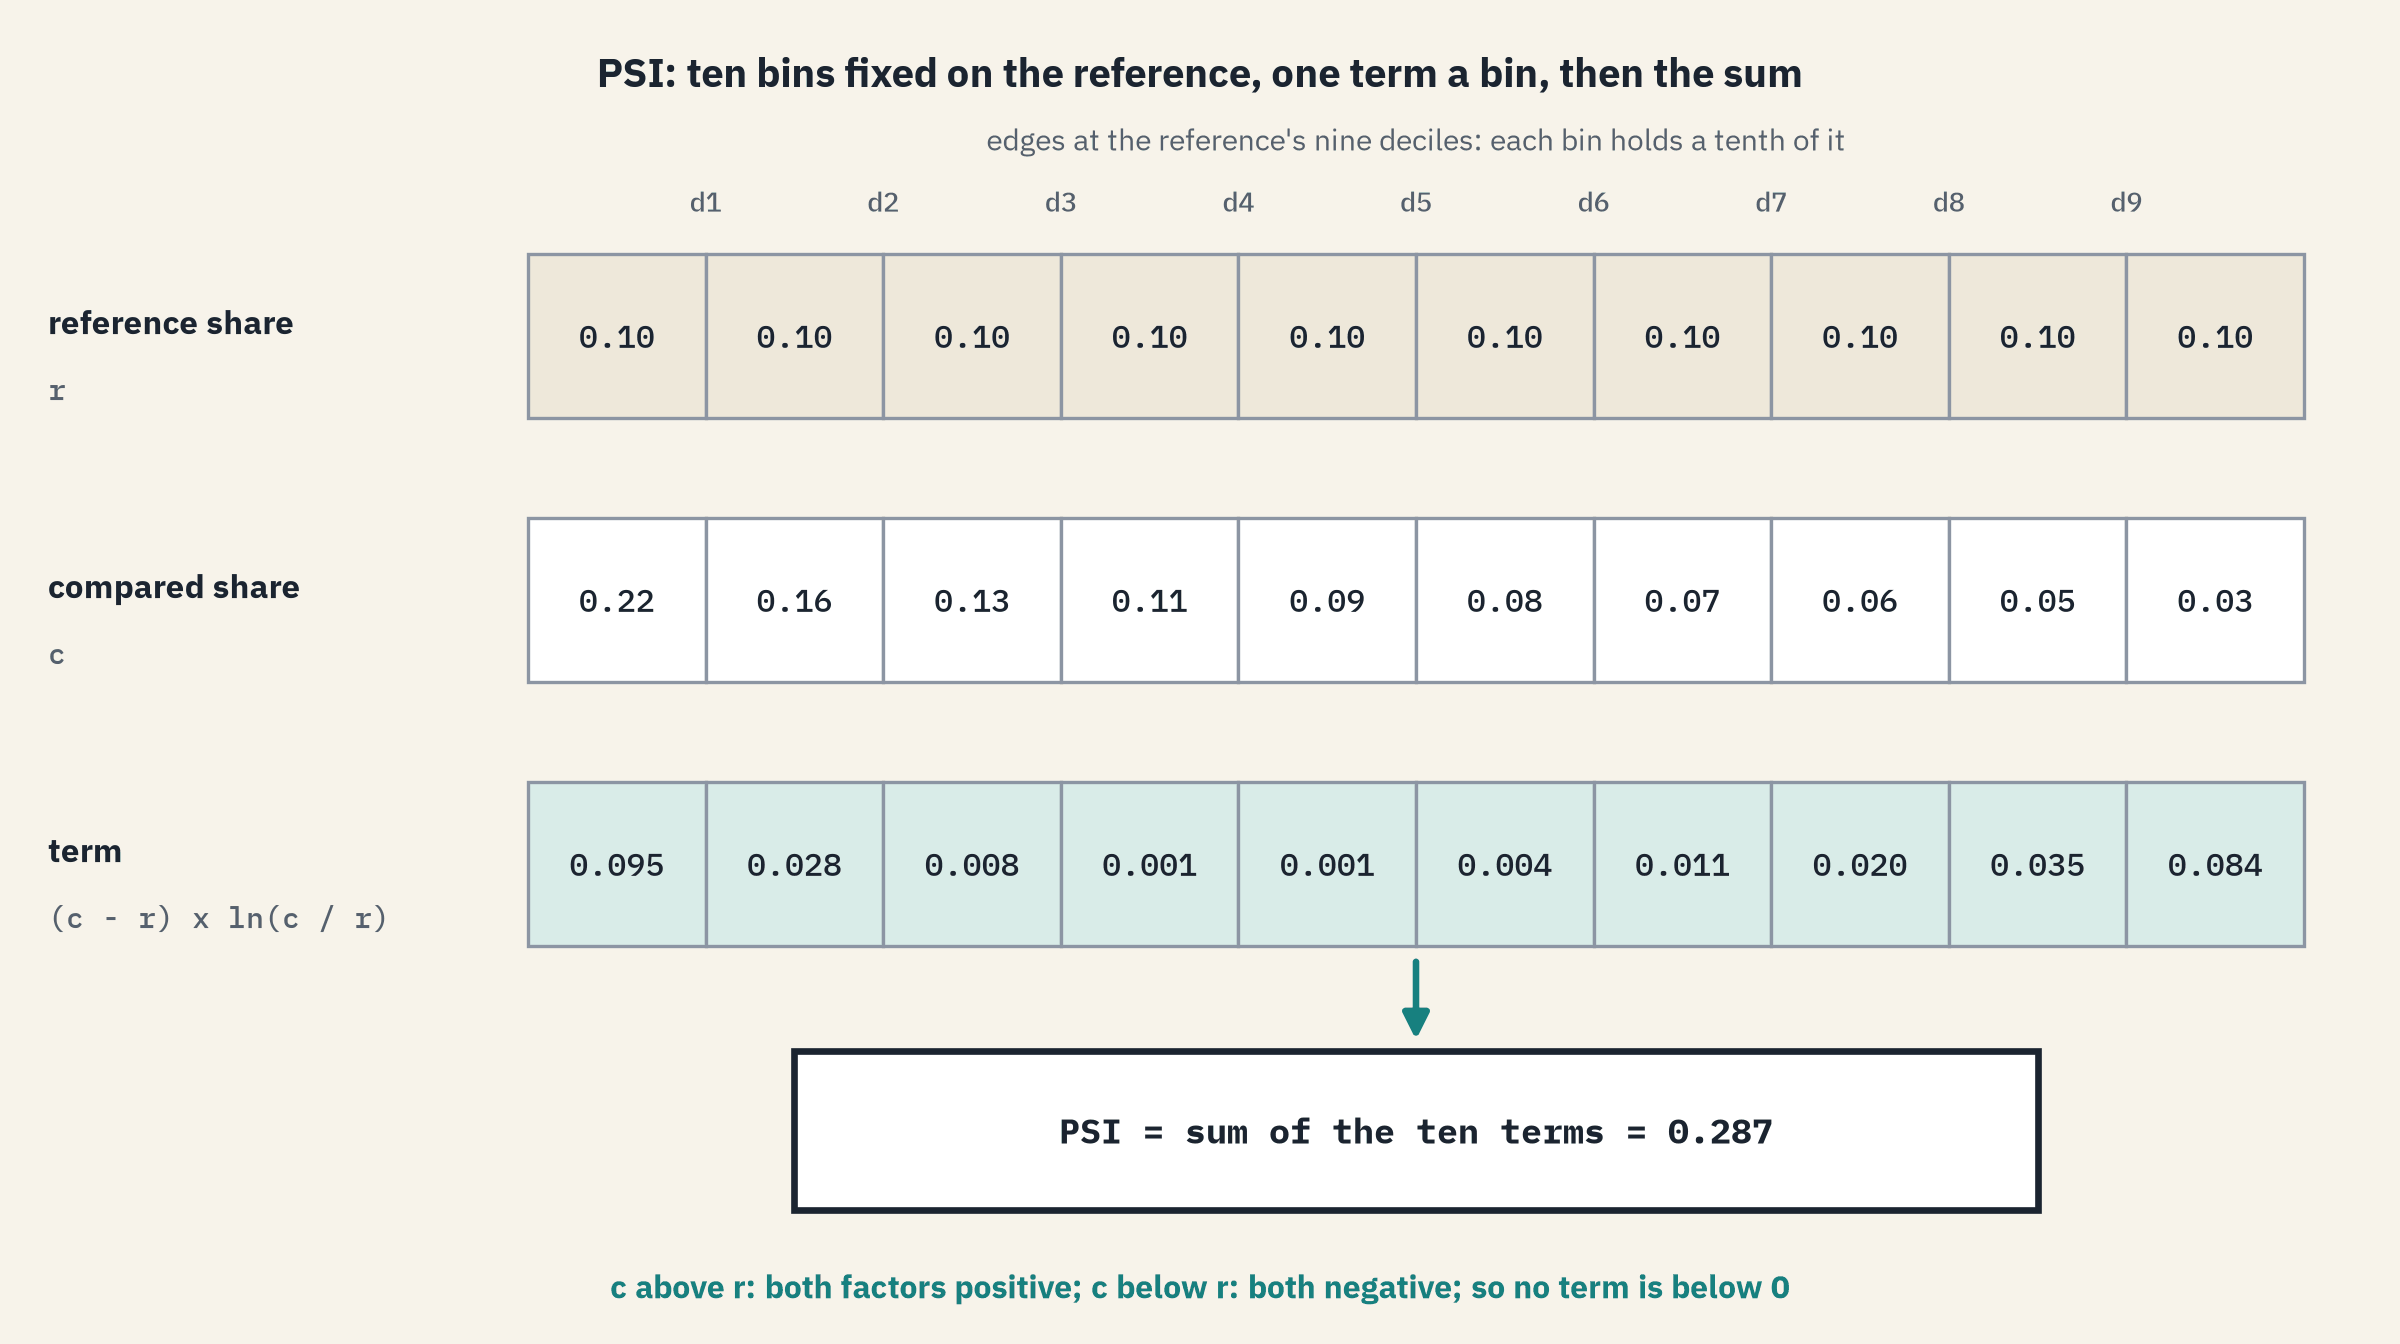

A term is never negative: the difference and the log share a sign, so PSI is 0 only when every bin's shares agree.

## Counting the Shares

`pd.cut` (Course 1) sorts each day into a bin.
With `-np.inf` and `np.inf` as the outer edges the end bins are open, and each bin holds the values above its left edge up to and including its right edge.
`.value_counts(normalize=True, sort=False)` then gives each bin's share, in bin order rather than largest first.

In [14]:
# each sample's share in the ten bins, in bin order
cuts = np.concatenate([[-np.inf], level_edges, [np.inf]])
reference_share = pd.cut(reference_level, cuts).value_counts(normalize=True, sort=False)
compared_share = pd.cut(compared_level, cuts).value_counts(normalize=True, sort=False)
pd.DataFrame({"reference": reference_share, "compared": compared_share}).round(3)

,reference,compared
10 Yr,,
"(-inf, 1.74]",0.105,0.540
"(1.74, 1.89]",0.097,0.081
"(1.89, 2.09]",0.099,0.064
"(2.09, 2.2]",0.105,0.016
"(2.2, 2.28]",0.106,0.003
"(2.28, 2.36]",0.102,0.007
"(2.36, 2.45]",0.089,0.020
"(2.45, 2.82]",0.103,0.115
"(2.82, 2.94]",0.098,0.029


The reference holds close to a tenth in every bin; days tied on an edge move a few between bins.

The compared years put 54.0 percent of their days in the lowest bin.

## Terms and the Sum

In [15]:
# each bin's term, and their sum: the PSI
terms = (compared_share - reference_share) * np.log(compared_share / reference_share)
print("Terms from", round(terms.min(), 4), "to", round(terms.max(), 4))
print("PSI of the 10 Yr level, 2019 to 2022 against 2015 to 2018:", round(terms.sum(), 4))

Terms from 0.0013 to 0.7135
PSI of the 10 Yr level, 2019 to 2022 against 2015 to 2018: 1.7173


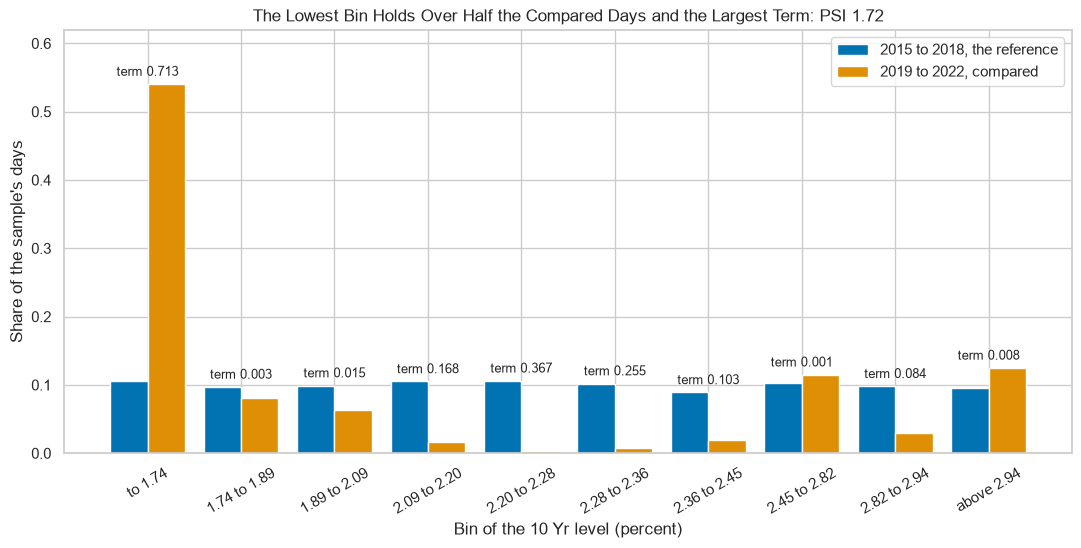

In [16]:
# the two samples' shares in each bin, each bin's term written above its pair
labels = [f"to {level_edges[0]:.2f}"] + [f"{a:.2f} to {b:.2f}" for a, b in zip(level_edges[:-1], level_edges[1:])] + [f"above {level_edges[-1]:.2f}"]
x = np.arange(10)
plt.figure(figsize=(13, 5.5))
plt.bar(x - 0.2, reference_share, width=0.4, label="2015 to 2018, the reference")
plt.bar(x + 0.2, compared_share, width=0.4, label="2019 to 2022, compared")
for i in x:
    plt.text(i, max(reference_share.iloc[i], compared_share.iloc[i]) + 0.012, f"term {terms.iloc[i]:.3f}", ha="center", fontsize=9)
plt.xticks(x, labels, rotation=30)
plt.ylim(0, 0.62)
plt.xlabel("Bin of the 10 Yr level (percent)")
plt.ylabel("Share of the sample's days")
plt.title(f"The Lowest Bin Holds Over Half the Compared Days and the Largest Term: PSI {terms.sum():.2f}")
plt.legend()
plt.show()

**One number for a mix: the 10 Yr level of 2019 to 2022 sat far from its reference's bins.**

## Three Small Functions

The day repeats these steps about twenty times, so they become three plain functions.
`np.unique` (Course 5) merges edges that land on the same value; the `floor` waits for the section after next.

In [17]:
def quantile_edges(reference, bins=10):
    """The reference's quantile edges for this many bins, equal edges merged."""
    return np.unique(np.quantile(reference, np.arange(1, bins) / bins))

def shares(sample, edges):
    """The sample's share in each bin, in bin order; the end bins are open."""
    return pd.cut(sample, np.concatenate([[-np.inf], edges, [np.inf]])).value_counts(normalize=True, sort=False)

def psi(reference, compared, edges, floor=0.0001):
    """PSI of the compared sample against the reference on fixed edges, each share floored first."""
    reference_share = shares(reference, edges).clip(lower=floor)
    compared_share = shares(compared, edges).clip(lower=floor)
    return ((compared_share - reference_share) * np.log(compared_share / reference_share)).sum()

# the function against the sum by hand
print("By function:", psi(reference_level, compared_level, quantile_edges(reference_level)), "| by hand:", terms.sum())

By function: 1.7173293118420834 | by hand: 1.7173293118420834


# The Level and Its Daily Change

**Predict 1**

The 10 Yr level's PSI is 1.72.

Q. The daily change on the same days, cut at its own reference deciles: what is its PSI? Write down a number.

## The Change Against Its Reference

In [18]:
# the daily change's PSI on its own reference edges, beside the level's
change_edges = quantile_edges(reference_change)
level_psi = psi(reference_level, compared_level, level_edges)
change_psi = psi(reference_change, compared_change, change_edges)
print(f"PSI: level {level_psi:.4f} | daily change {change_psi:.4f}")

PSI: level 1.7173 | daily change 0.0408


A level wanders into ranges its reference never held.

A day's change in bp kept close to the same shape in both periods.

## Two Histograms Overlaid

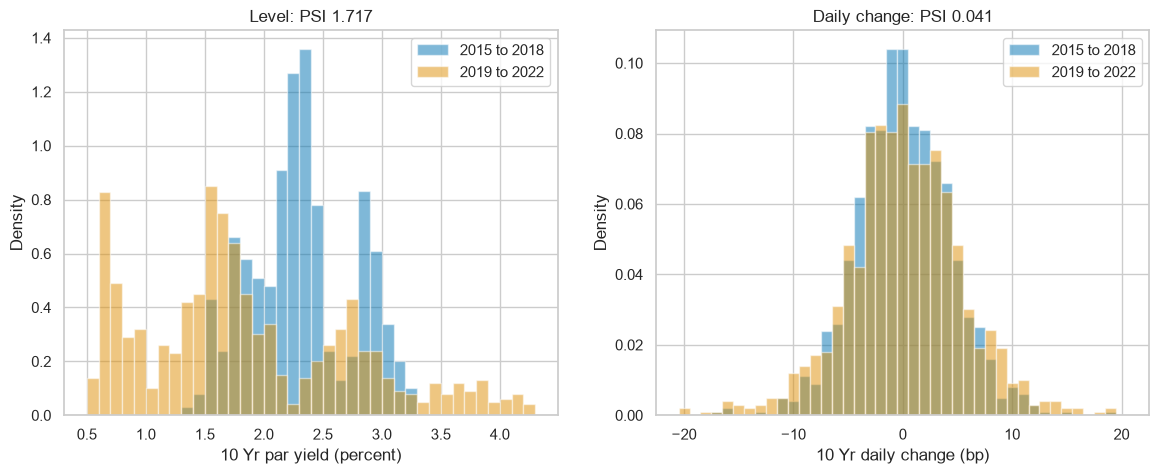

In [19]:
# each pair of samples on shared bins; density=True gives each an area of 1, so samples of different sizes compare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
panels = [("Level", reference_level, compared_level, np.linspace(0.5, 4.3, 39), "10 Yr par yield (percent)", level_psi),
          ("Daily change", reference_change, compared_change, np.arange(-20.5, 21.5), "10 Yr daily change (bp)", change_psi)]
for ax, (name, reference, compared, bins, unit, value) in zip(axes, panels):
    ax.hist(reference, bins=bins, density=True, alpha=0.5, label="2015 to 2018")
    ax.hist(compared, bins=bins, density=True, alpha=0.5, label="2019 to 2022")
    ax.set(xlabel=unit, ylabel="Density", title=f"{name}: PSI {value:.3f}")
    ax.legend()
plt.show()

## Each Sample's Cumulative Share

A **P-P plot** draws the compared sample's cumulative share against the reference's at every value: the share of each at or below it.
The diagonal is no move.
It pairs two shares, as Course 4's Day 8 ROC curve does.
`np.searchsorted(np.sort(sample), values, side="right")` counts the sample's values at or below each value (Course 3's `Index.searchsorted`).

In [20]:
def cumulative_share(sample, values):
    """The share of the sample at or below each value."""
    return np.searchsorted(np.sort(sample), values, side="right") / len(sample)

# the compared sample's cumulative share at the reference's nine edges
print("Level, compared:", cumulative_share(compared_level, level_edges).round(3))
print("Change, compared:", cumulative_share(compared_change, change_edges).round(3))
print("Change, reference:", cumulative_share(reference_change, change_edges).round(3))

Level, compared: [0.54  0.621 0.685 0.701 0.704 0.711 0.731 0.846 0.875]
Change, compared: [0.169 0.291 0.373 0.453 0.54  0.611 0.682 0.82  0.868]
Change, reference: [0.127 0.271 0.352 0.456 0.561 0.643 0.724 0.862 0.906]


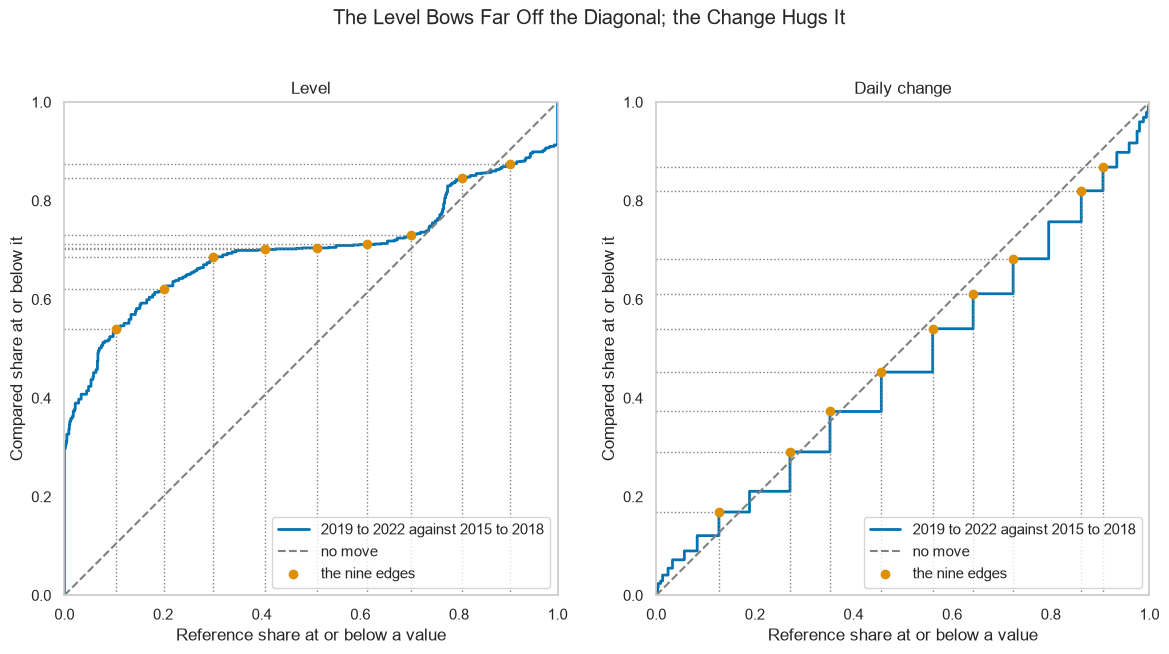

In [21]:
# P-P plots as steps, the diagonal, and the dotted grid where PSI reads the curve: at the reference's nine edges
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (name, reference, compared, edges) in zip(axes, [("Level", reference_level, compared_level, level_edges),
                                                         ("Daily change", reference_change, compared_change, change_edges)]):
    values = np.sort(np.concatenate([reference, compared]))
    ax.plot(cumulative_share(reference, values), cumulative_share(compared, values), drawstyle="steps-post", linewidth=2, label="2019 to 2022 against 2015 to 2018")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no move")
    at_x, at_y = cumulative_share(reference, edges), cumulative_share(compared, edges)
    ax.vlines(at_x, 0, at_y, color="gray", linestyle=":", linewidth=1)
    ax.hlines(at_y, 0, at_x, color="gray", linestyle=":", linewidth=1)
    ax.scatter(at_x, at_y, color="C1", zorder=3, label="the nine edges")
    # set_aspect("equal") gives both axes one scale (Day 3); the theme's grid is turned off so the dotted one reads
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Reference share at or below a value", ylabel="Compared share at or below it", title=name)
    ax.legend(loc="lower right")
fig.suptitle("The Level Bows Far Off the Diagonal; the Change Hugs It")
plt.show()

The level: 0.540 of the compared days sat at or below the reference's 10th percentile, and the share rose only from 0.685 to 0.731 across its 30th to 70th.

The change: the compared shares ran from 0.169 to 0.868 at the edges, beside the reference's own 0.127 to 0.906.

**The level moved out of its reference; the change kept its shape, so a model that read daily changes in 2019 to 2022 met inputs like those it was built on.**

# The Empty Bin and Its Floor

## One Quarter in One Bin

In [22]:
# the first quarter of 2021: its days' shares in the level's ten bins
quarter = level.loc["2021-01-01":"2021-03-31"]
print(len(quarter), "days | shares:", shares(quarter, level_edges).round(3).tolist())

61 days | shares: [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


## A Log of Zero

Nine of the quarter's bins are empty, and an empty bin's term takes the log of 0 over a reference share of 0.1.

In [23]:
# an empty bin's ratio, 0 / 0.1, inside math's natural log
math.log(0 / 0.1)

ValueError: math domain error

The log of 0 has no value, so one empty bin leaves PSI with none.

A **floor** raises any share below it to the floor before the log, with `.clip(lower=)` (Course 1's `.clip(upper=)` turned around).
`psi` floors both samples at 0.0001.

In [24]:
# the quarter's PSI with the floor at 0.0001
print("2021 Q1 at a floor of 0.0001:", round(psi(reference_level, quarter, level_edges), 4))

2021 Q1 at a floor of 0.0001: 8.1895


**Predict 2**

At a floor of 0.0001 the quarter's PSI is 8.19.

Q. At a floor of 0.000001, a hundred times smaller, what is it? Write down a number.

## Every Floor

In [25]:
# the quarter and the whole compared sample at five floors
FLOORS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
floor_table = pd.DataFrame({"2021 Q1": [psi(reference_level, quarter, level_edges, floor) for floor in FLOORS],
                            "2019 to 2022": [psi(reference_level, compared_level, level_edges, floor) for floor in FLOORS]}, index=FLOORS)
floor_table.round(4)

,2021 Q1,2019 to 2022
0.000001,12.3173,1.7173
0.000010,10.2557,1.7173
0.000100,8.1895,1.7173
0.001000,6.0935,1.7173
0.010000,3.8675,1.5357


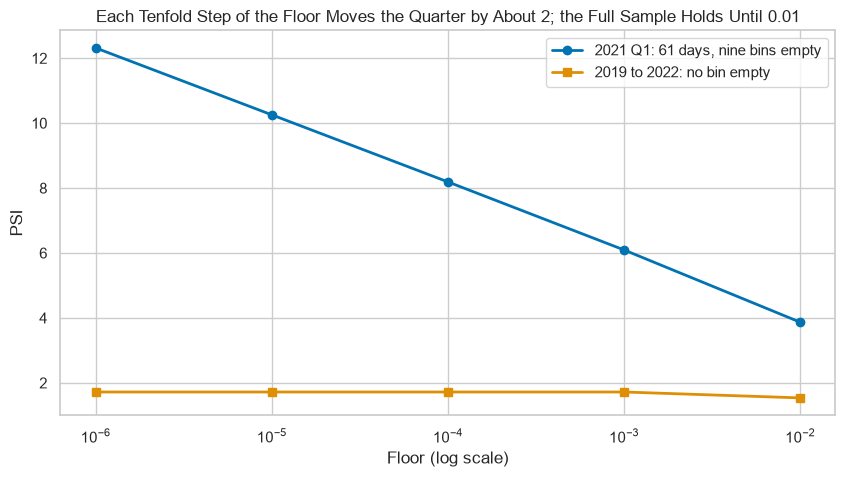

In [26]:
# PSI against the floor on a log axis
plt.figure(figsize=(10, 5))
plt.plot(FLOORS, floor_table["2021 Q1"], marker="o", linewidth=2, label="2021 Q1: 61 days, nine bins empty")
plt.plot(FLOORS, floor_table["2019 to 2022"], marker="s", linewidth=2, label="2019 to 2022: no bin empty")
plt.xscale("log")
plt.xlabel("Floor (log scale)")
plt.ylabel("PSI")
plt.title("Each Tenfold Step of the Floor Moves the Quarter by About 2; the Full Sample Holds Until 0.01")
plt.legend()
plt.show()

Each empty bin adds about 0.1 x ln(0.1 / floor), so nine of them move the quarter by 0.9 x ln(10), about 2.07, at each tenfold step.

The full sample's smallest share, 0.003, sits above every floor but 0.01.

**Past an empty bin a PSI's size is the floor's: read it as outside the reference, and keep the floor far below any real share.**

# The Number and Shape of the Bins

## Quantile and Equal-Width Bins

**Equal-width bins** cut the reference's range into equal steps, `np.linspace` from its lowest value to its highest; quantile bins hold equal shares.

In [27]:
# PSI at 5, 10, 20 and 50 bins asked, quantile and equal width, for the level and the change
bin_rows = []
for bins in [5, 10, 20, 50]:
    row = {"bins asked": bins}
    for name, reference, compared in [("level", reference_level, compared_level), ("change", reference_change, compared_change)]:
        row[name + " quantile"] = psi(reference, compared, quantile_edges(reference, bins))
        row[name + " equal width"] = psi(reference, compared, np.linspace(reference.min(), reference.max(), bins + 1)[1:-1])
    bin_rows.append(row)
bin_table = pd.DataFrame(bin_rows).set_index("bins asked")
bin_table.round(3)

,level quantile,level equal width,change quantile,change equal width
bins asked,,,,
5,1.218,1.513,0.020,0.063
10,1.717,1.935,0.041,0.080
20,2.025,2.484,0.066,0.108
50,2.585,3.068,0.085,0.147


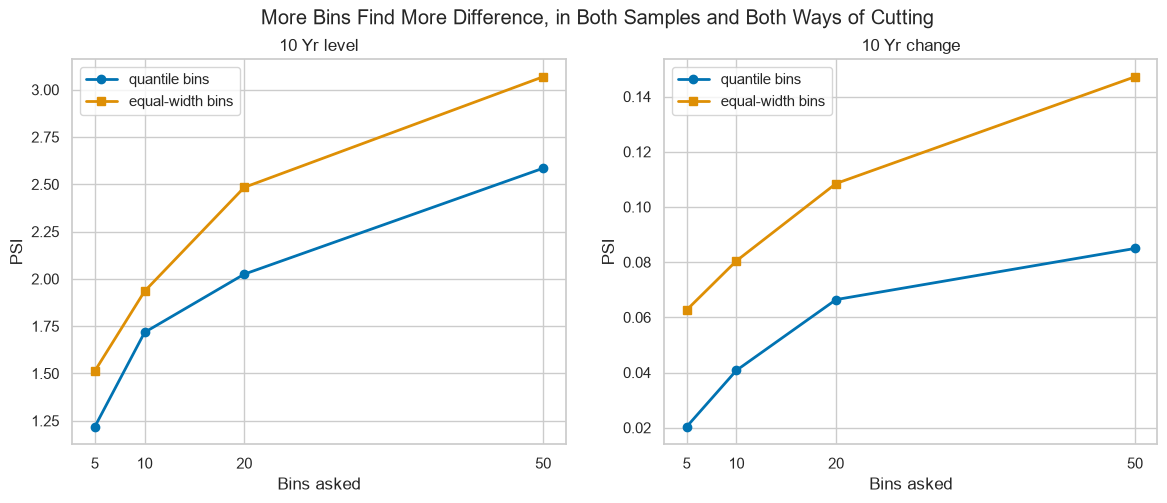

In [28]:
# the same table as two panels
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["level", "change"]):
    ax.plot(bin_table.index, bin_table[name + " quantile"], marker="o", linewidth=2, label="quantile bins")
    ax.plot(bin_table.index, bin_table[name + " equal width"], marker="s", linewidth=2, label="equal-width bins")
    ax.set(xticks=bin_table.index, xlabel="Bins asked", ylabel="PSI", title=f"10 Yr {name}")
    ax.legend()
fig.suptitle("More Bins Find More Difference, in Both Samples and Both Ways of Cutting")
plt.show()

## Bins Asked and Bins Used

In [29]:
# the change's quantiles land on whole bp, so equal edges merge
for bins in [5, 10, 20, 50]:
    print(bins, "asked |", len(quantile_edges(reference_change, bins)) + 1, "used")

5 asked | 5 used
10 asked | 10 used
20 asked | 14 used
50 asked | 19 used


At 50 bins asked the change has only 19, since a quantile of whole bp is often the same whole bp.

**More bins find more difference, so the count is set before any comparison: ten quantile bins for the rest of the day.**

# PSI Quarter by Quarter

## Every Quarter Against One Reference

A monitor reads one **window** at a time against one fixed reference.
`level.index.to_period("Q")` labels each day with its quarter (Course 3's `to_period("M")`).

In [30]:
# the quarters of 2015 to 2022, those inside the reference, and the days a quarter
quarters = level.index.to_period("Q")
days_a_quarter = level.groupby(quarters).size()
print(quarters.nunique(), "quarters |", reference_level.index.to_period("Q").nunique(), "inside the reference | days a quarter:", days_a_quarter.min(), "to", days_a_quarter.max())

32 quarters | 16 inside the reference | days a quarter: 61 to 64


**Predict 3**

The 16 quarters of 2015 to 2018 are pieces of the reference itself.

Q. What is the median PSI of the daily change over those 16 quarters, each against the full reference? Write down a number.

## The Reference's Own Quarters

In [31]:
# each quarter's PSI against the one reference and its edges: the level, and the change on the same days
quarterly = {}
for label, days in pd.DataFrame({"level": level, "change": change}).groupby(quarters):
    quarterly[label] = {"level": psi(reference_level, days["level"], level_edges), "change": psi(reference_change, days["change"].dropna(), change_edges),
                        "fullest level bin": shares(days["level"], level_edges).max()}
quarterly = pd.DataFrame(quarterly).T
inside, after = quarterly.loc[:"2018Q4"], quarterly.loc["2019Q1":]
print(f"Change inside the reference: median {inside['change'].median():.3f}, from {inside['change'].min():.3f} to {inside['change'].max():.3f} ({inside['change'].idxmax()})")
print(f"Change in 2019 to 2022: median {after['change'].median():.3f} | above every quarter inside:", after.index[after["change"] > inside["change"].max()].astype(str).tolist())
print(f"Level: median {inside['level'].median():.2f} inside, {after['level'].median():.2f} after")
print("Quarters with every level day in one bin:", quarterly.index[quarterly["fullest level bin"] == 1].astype(str).tolist())

Change inside the reference: median 0.217, from 0.073 to 0.389 (2018Q4)
Change in 2019 to 2022: median 0.183 | above every quarter inside: ['2020Q3', '2022Q2', '2022Q3', '2022Q4']
Level: median 5.08 inside, 7.75 after
Quarters with every level day in one bin: ['2016Q3', '2020Q2', '2020Q3', '2020Q4', '2021Q1', '2021Q2', '2021Q3', '2021Q4', '2022Q4']


About 62 days in ten bins is a small sample: quarters of the reference itself read up to 0.39 on the change.

A quarter of a wandering level covers a slice of four years' range, so even the reference's own quarters read a median of 5.08, and in 2016 Q3 every day sat in one bin.

> STORY: In April 2018 Bilal Yurdakul's PhD dissertation at Western Michigan University studied the statistical properties of PSI.
> Its abstract lists the rules of thumb in use: PSI below 0.10 means "little shift", and 0.25 marks "significant shift, action required".
> The band between the two does not display legibly on the page, so it is not quoted here.
> The abstract adds that these benchmarks are used "without reference to Type I or Type II error rates".
> Source: B. Yurdakul, "Statistical Properties of Population Stability Index", PhD dissertation, Western Michigan University, April 2018, abstract, https://scholarworks.wmich.edu/dissertations/3208/ (read 2026-11-18)

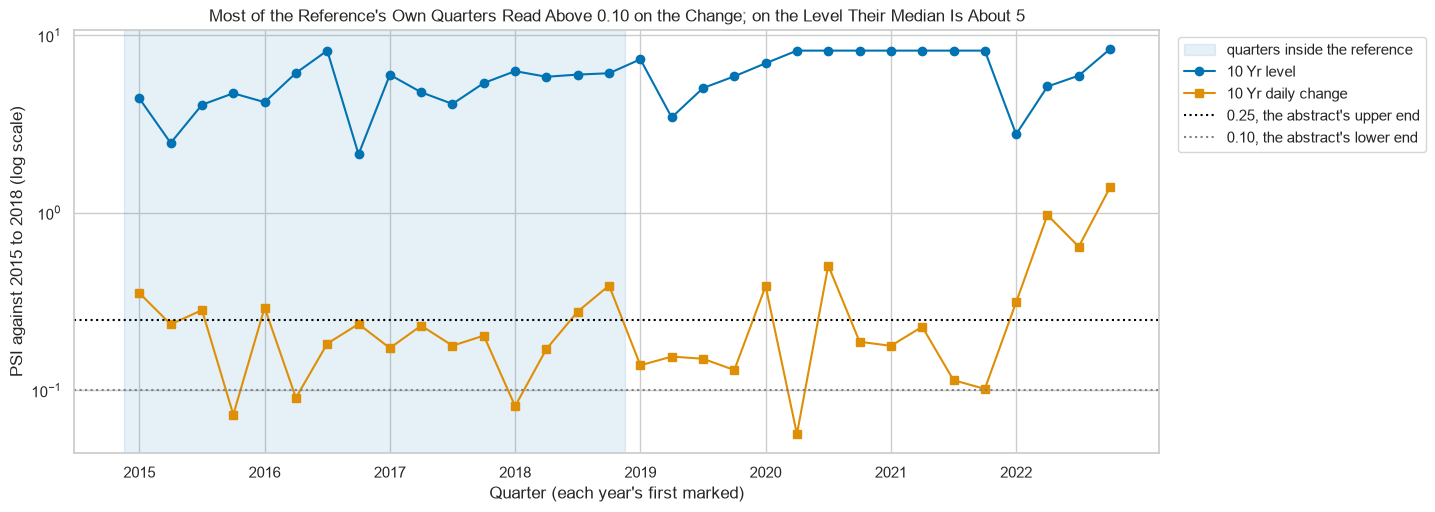

In [32]:
# every quarter's PSI on a log axis, the reference quarters shaded, the abstract's 0.10 and 0.25 dotted for reading
x = np.arange(len(quarterly))
plt.figure(figsize=(14, 5.5))
plt.axvspan(-0.5, 15.5, color="C0", alpha=0.1, label="quarters inside the reference")
plt.plot(x, quarterly["level"], marker="o", linewidth=1.5, label="10 Yr level")
plt.plot(x, quarterly["change"], marker="s", linewidth=1.5, label="10 Yr daily change")
plt.axhline(0.25, color="black", linestyle=":", linewidth=1.5, label="0.25, the abstract's upper end")
plt.axhline(0.10, color="gray", linestyle=":", linewidth=1.5, label="0.10, the abstract's lower end")
plt.yscale("log")
plt.xticks(x[::4], [str(label.year) for label in quarterly.index[::4]])
plt.xlabel("Quarter (each year's first marked)")
plt.ylabel("PSI against 2015 to 2018 (log scale)")
plt.title("Most of the Reference's Own Quarters Read Above 0.10 on the Change; on the Level Their Median Is About 5")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [33]:
# the reference's own quarters of the change above the abstract's two ends
print("Change, quarters inside the reference above 0.10:", (inside["change"] > 0.10).sum(), "| above 0.25:", (inside["change"] > 0.25).sum(), "| of", len(inside))

Change, quarters inside the reference above 0.10: 13 | above 0.25: 5 | of 16


Read with no sense of a short window's own noise, either end would mark quarters where the reference was compared with itself.

## Your Turn: Any Quarter

In [34]:
# one quarter's daily changes against the reference, bin by bin
def draw_quarter(quarter="2022Q4"):
    days = change[change.index.to_period("Q") == quarter]
    x = np.arange(len(change_edges) + 1)
    plt.figure(figsize=(11, 4.5))
    plt.bar(x - 0.2, shares(reference_change, change_edges), width=0.4, label="2015 to 2018, the reference")
    plt.bar(x + 0.2, shares(days, change_edges), width=0.4, label=f"{quarter}, {len(days)} days")
    plt.xticks(x, [f"to {change_edges[0]:.0f}"] + [f"{b:.0f}" for b in change_edges[1:]] + [f"above {change_edges[-1]:.0f}"])
    plt.ylim(0, 0.45)
    plt.xlabel("Bin of the daily change (bp, each bin's top edge)")
    plt.ylabel("Share of days")
    plt.title(f"{quarter}: PSI {psi(reference_change, days, change_edges):.3f} Against the Reference")
    plt.legend()
    plt.show()

In [35]:
# your turn: pick a quarter
interact(draw_quarter, quarter=[str(label) for label in quarterly.index]);

interactive(children=(Dropdown(description='quarter', index=31, options=('2015Q1', '2015Q2', '2015Q3', '2015Q4…

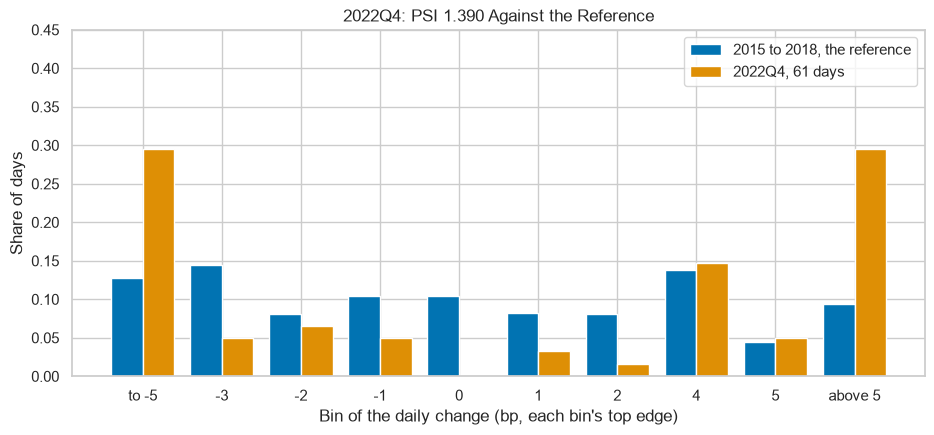

In [36]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_quarter(quarter="2022Q4")

**A threshold read without the window's own noise flags quarters where nothing moved.**

# The Cohort's Entering Firms

## Fixing the Reference Firms' Edges

In [37]:
# each input's ten bins, cut on the 2,508 reference firms before a compared firm is read
INPUTS = ["rating_score", "leverage", "coverage"]
cohort_edges = {name: quantile_edges(reference_firms[name]) for name in INPUTS}
print("Rating score edges:", cohort_edges["rating_score"])

# only now the firms entering in study years 11 to 14
compared_firms = entrants[entrants["study_year"] >= 11]
print("Compared firms:", len(compared_firms))

Rating score edges: [ 5.   7.   8.   9.  10.  11.2 13.  14.  16. ]
Compared firms: 996


Rating score takes whole notches, yet its edges stay apart, so all ten bins are used.

## Each Input's PSI

In [38]:
# each input's PSI and median, reference against compared, largest PSI first
cohort_rows = {}
for name in INPUTS:
    cohort_rows[name] = {"PSI": psi(reference_firms[name], compared_firms[name], cohort_edges[name]),
                         "reference median": reference_firms[name].median(), "compared median": compared_firms[name].median()}
pd.DataFrame(cohort_rows).T.sort_values("PSI", ascending=False).round(3)

,PSI,reference median,compared median
leverage,0.333,4.125,4.945
rating_score,0.232,10.000,12.000
coverage,0.122,5.855,4.720


The compared firms carry more leverage, a lower rating (a higher score) and less coverage.

## Entry Year by Entry Year

In [39]:
# each entry year's firms against the reference firms, input by input
by_year = {}
for year, firms in entrants.groupby("study_year"):
    by_year[year] = {name: psi(reference_firms[name], firms[name], cohort_edges[name]) for name in INPUTS}
by_year = pd.DataFrame(by_year).T
print("Largest PSI of a reference year against its own reference:", round(by_year.loc[1:10].max().max(), 3))
by_year.loc[11:].round(3)

Largest PSI of a reference year against its own reference: 0.062


,rating_score,leverage,coverage
11,0.126,0.110,0.083
12,0.240,0.268,0.104
13,0.278,0.434,0.148
14,0.483,0.856,0.414


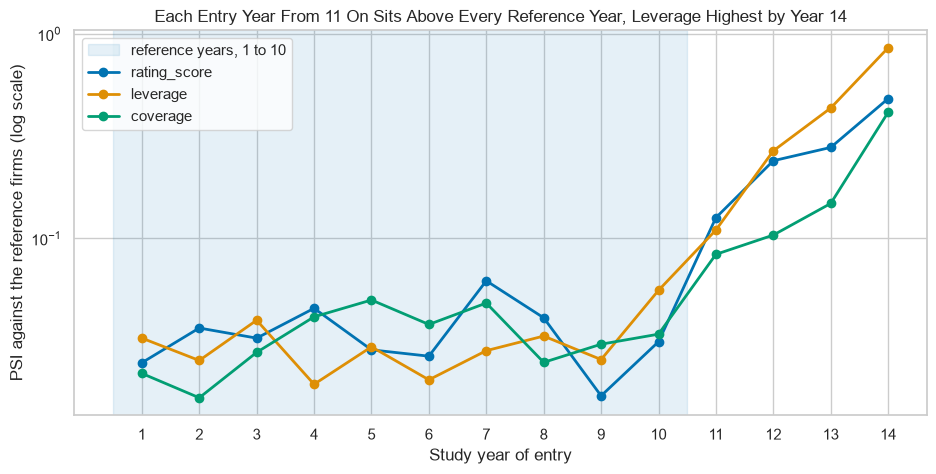

In [40]:
# PSI by entry year on a log axis, the reference years shaded
plt.figure(figsize=(11, 5))
plt.axvspan(0.5, 10.5, color="C0", alpha=0.1, label="reference years, 1 to 10")
for name in INPUTS:
    plt.plot(by_year.index, by_year[name], marker="o", linewidth=2, label=name)
plt.yscale("log")
plt.xticks(by_year.index)
plt.xlabel("Study year of entry")
plt.ylabel("PSI against the reference firms (log scale)")
plt.title("Each Entry Year From 11 On Sits Above Every Reference Year, Leverage Highest by Year 14")
plt.legend(loc="upper left")
plt.show()

About 250 firms a year leave the reference years' own PSI at up to 0.062: that is its noise.

From study year 11 each input climbs year by year; leverage reaches 0.856 for the year-14 entrants.

**Predict 4**

The compared firms' median leverage is 4.945 times against the reference's 4.125, and their median coverage 4.720 times against 5.855.

Q. Sketch, for each input, the compared decile less the reference decile at the 10th, 20th, ... 90th percentiles: one line across nine points.

## Where in the Distribution

A **shift function** draws the compared decile less the reference decile at each of the nine deciles.
Each difference gets a 95 percent bootstrap interval (Course 4's Day 3, Course 5's Day 10): 2,000 resamples of each sample with `rng.choice`.

In [41]:
# each input's nine decile differences, with the 2.5th and 97.5th percentiles of 2,000 resampled differences
DECILES = np.arange(1, 10) / 10
rng = np.random.default_rng(SEED)
shift = {}
for name in ["leverage", "coverage"]:
    reference, compared = reference_firms[name].to_numpy(), compared_firms[name].to_numpy()
    resampled = []
    for _ in range(2_000):
        resampled_reference = rng.choice(reference, len(reference))
        resampled.append(np.quantile(rng.choice(compared, len(compared)), DECILES) - np.quantile(resampled_reference, DECILES))
    low, high = np.quantile(resampled, [0.025, 0.975], axis=0)
    shift[name] = pd.DataFrame({"reference decile": np.quantile(reference, DECILES), "difference": np.quantile(compared, DECILES) - np.quantile(reference, DECILES), "low": low, "high": high}, index=DECILES)
pd.concat({name: shift[name][["difference", "low", "high"]] for name in shift}, axis=1).round(2)

leverage               coverage            
    difference   low  high difference   low  high
0.1       0.78  0.57  0.97      -0.54 -0.72 -0.37
0.2       0.79  0.65  0.98      -0.67 -0.87 -0.48
0.3       0.81  0.68  0.95      -0.88 -1.07 -0.68
0.4       0.81  0.68  0.96      -1.00 -1.29 -0.68
0.5       0.82  0.70  0.97      -1.14 -1.45 -0.83
0.6       0.85  0.73  0.97      -1.49 -1.81 -1.13
0.7       0.84  0.70  1.01      -1.54 -2.02 -1.22
0.8       0.84  0.72  0.96      -1.97 -2.78 -1.29
0.9       0.75  0.62  0.87      -2.35 -3.40 -1.51

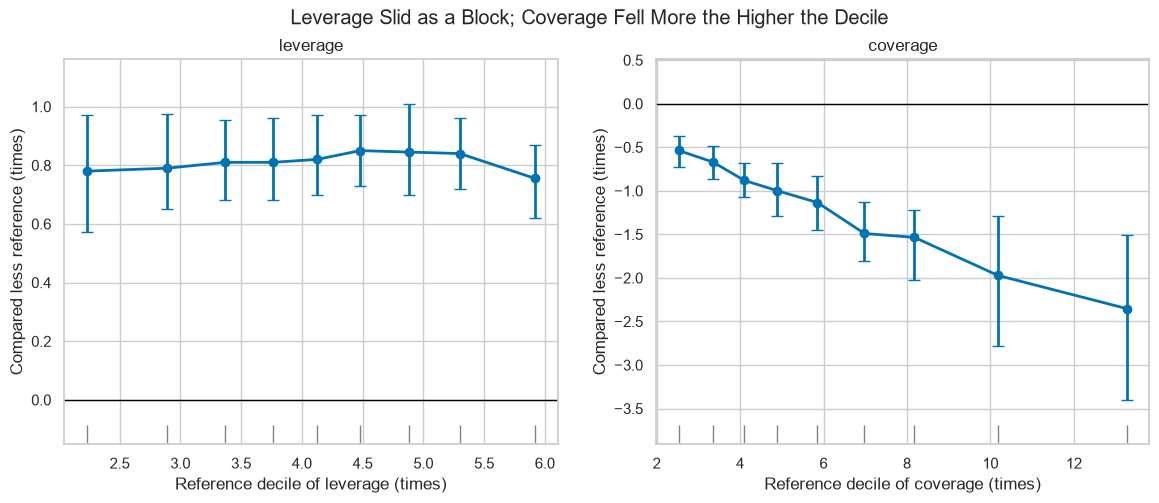

In [42]:
# the shift functions: differences with their intervals at the reference deciles, a zero line, the deciles as a rug
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["leverage", "coverage"]):
    table = shift[name]
    ax.errorbar(table["reference decile"], table["difference"], yerr=[table["difference"] - table["low"], table["high"] - table["difference"]], marker="o", capsize=4, linewidth=2)
    ax.axhline(0, color="black", linewidth=1)
    sns.rugplot(x=table["reference decile"], height=0.05, color="gray", ax=ax)
    ax.set(xlabel=f"Reference decile of {name} (times)", ylabel="Compared less reference (times)", title=name)
fig.suptitle("Leverage Slid as a Block; Coverage Fell More the Higher the Decile")
plt.show()

In [43]:
# each compared coverage decile as a share of the reference's
print("Compared coverage decile over reference decile:", (np.quantile(compared_firms["coverage"], DECILES) / shift["coverage"]["reference decile"].to_numpy()).round(2))

Compared coverage decile over reference decile: [0.79 0.8  0.79 0.8  0.81 0.79 0.81 0.81 0.82]


Leverage's gap stayed near 0.8 times at every decile, and every interval sat above zero.

Coverage's gap grew with the decile, while each compared decile stayed close to 0.8 of the reference's.

The generator makes coverage from leverage (`DATA.md`), so about 0.8 more leverage went with about a fifth less coverage.

**PSI found the planted tilt in rating score and leverage, and its trace in coverage: leverage slid as a block and coverage shrank in proportion.**

# PSI Beside the KS Test and Jensen-Shannon

## The KS Statistic

The **Kolmogorov-Smirnov (KS) statistic** is the largest vertical gap between two samples' ECDFs (Course 4's Day 2), with no bins.
On a P-P plot it is the curve's largest distance above or below the diagonal.
`ks_2samp` returns it with a p-value that tests whether the two samples came from one population (Course 4's Day 3).

In [44]:
# KS on coverage: the statistic, its p-value, and where the largest gap sits
test = ks_2samp(reference_firms["coverage"], compared_firms["coverage"])
values = np.sort(np.concatenate([reference_firms["coverage"], compared_firms["coverage"]]))
at_x, at_y = cumulative_share(reference_firms["coverage"], values), cumulative_share(compared_firms["coverage"], values)
widest = np.abs(at_y - at_x).argmax()
print(f"KS {test.statistic:.3f} | p-value {test.pvalue:.0e} | at coverage {values[widest]:.2f} times: {at_x[widest]:.3f} of the reference and {at_y[widest]:.3f} of the compared firms at or below")

KS 0.142 | p-value 6e-13 | at coverage 5.76 times: 0.492 of the reference and 0.634 of the compared firms at or below


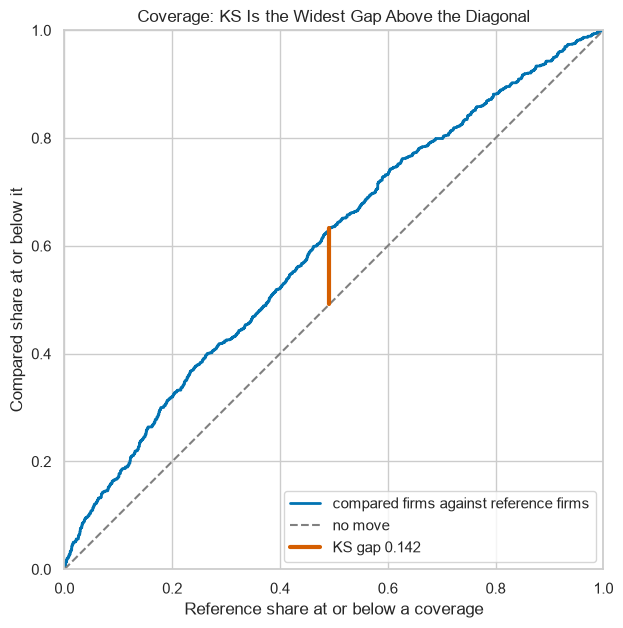

In [45]:
# coverage's P-P plot with the KS gap drawn from the diagonal to the curve
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(at_x, at_y, drawstyle="steps-post", linewidth=2, label="compared firms against reference firms")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no move")
ax.plot([at_x[widest], at_x[widest]], [at_x[widest], at_y[widest]], color="C3", linewidth=3, label=f"KS gap {test.statistic:.3f}")
ax.set_aspect("equal")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Reference share at or below a coverage", ylabel="Compared share at or below it", title="Coverage: KS Is the Widest Gap Above the Diagonal")
ax.legend(loc="lower right")
plt.show()

## Jensen-Shannon

**Jensen-Shannon** compares the two samples' shares on the same bins, each against their average mix, so an empty bin needs no floor.
`jensenshannon(p, q, base=2)` returns the Jensen-Shannon **distance**, the square root of the divergence, from 0 for the same shares to 1 for no bin shared.

In [46]:
# Jensen-Shannon on coverage's ten bins, with no floor
print("Jensen-Shannon distance, coverage:", round(jensenshannon(shares(reference_firms["coverage"], cohort_edges["coverage"]), shares(compared_firms["coverage"], cohort_edges["coverage"]), base=2), 3))

Jensen-Shannon distance, coverage: 0.147


## Six Comparisons in One Table

In [47]:
# PSI, KS with its p-value, and Jensen-Shannon for six pairs, each on its reference's ten bins
pairs = {"10 Yr level": (reference_level, compared_level), "10 Yr change": (reference_change, compared_change), "2021 Q1 level": (reference_level, quarter)}
for name in INPUTS:
    pairs[name] = (reference_firms[name], compared_firms[name])
comparison, p_values = {}, {}
for name, (reference, compared) in pairs.items():
    edges = quantile_edges(reference)
    test = ks_2samp(reference, compared)
    comparison[name] = {"PSI": psi(reference, compared, edges), "KS": test.statistic,
                        "Jensen-Shannon": jensenshannon(shares(reference, edges), shares(compared, edges), base=2)}
    # Day 2's rule: a p-value below 0.0001 in the .0e format
    p_values[name] = f"{test.pvalue:.0e}" if test.pvalue < 0.0001 else f"{test.pvalue:.4f}"
comparison = pd.DataFrame(comparison).T.round(3)
comparison["KS p-value"] = pd.Series(p_values)
comparison

,PSI,KS,Jensen-Shannon,KS p-value
10 Yr level,1.717,0.437,0.509,1e-86
10 Yr change,0.041,0.042,0.086,0.3301
2021 Q1 level,8.190,0.895,0.866,3e-54
rating_score,0.232,0.181,0.202,6e-21
leverage,0.333,0.235,0.241,7e-35
coverage,0.122,0.142,0.147,6e-13


The p-value measures evidence, not size: with about a thousand rows a side or more, a small gap is already far from chance.

KS and Jensen-Shannon stop at 1, and the quarter sits near it, where PSI's 8.19 is the floor's.

The three order the cohort's inputs the same way.

**Predict 5**

Move each reference day of the 10 Yr level up to the top of its own bin; the top bin's days go to the reference's highest level.
Most days move, some by tens of bp.

Q. What is the PSI of the moved days against the reference? Write down a number.

## Moving Every Day to the Top of Its Bin

`pd.cut(..., labels=)` (Course 1) gives each day its bin's label: with the bins' upper edges as labels, each day takes its bin's top.

In [48]:
# each reference day moved to the top of its bin
tops = np.concatenate([level_edges, [reference_level.max()]])
moved = pd.cut(reference_level, cuts, labels=tops).astype(float)
print(f"Days moved: {100 * (moved != reference_level).mean():.1f} percent | {100 * (moved - reference_level).mean():.1f} bp on average, at most {100 * (moved - reference_level).max():.0f} bp")

# PSI, Jensen-Shannon and KS of the moved days against the reference
test = ks_2samp(reference_level, moved)
print(f"PSI {psi(reference_level, moved, level_edges):.4f} | Jensen-Shannon {jensenshannon(shares(reference_level, level_edges), shares(moved, level_edges), base=2):.4f} | KS {test.statistic:.3f}, p-value {test.pvalue:.4f}")

Days moved: 92.3 percent | 9.1 bp on average, at most 37 bp
PSI 0.0000 | Jensen-Shannon 0.0000 | KS 0.099, p-value 0.0001


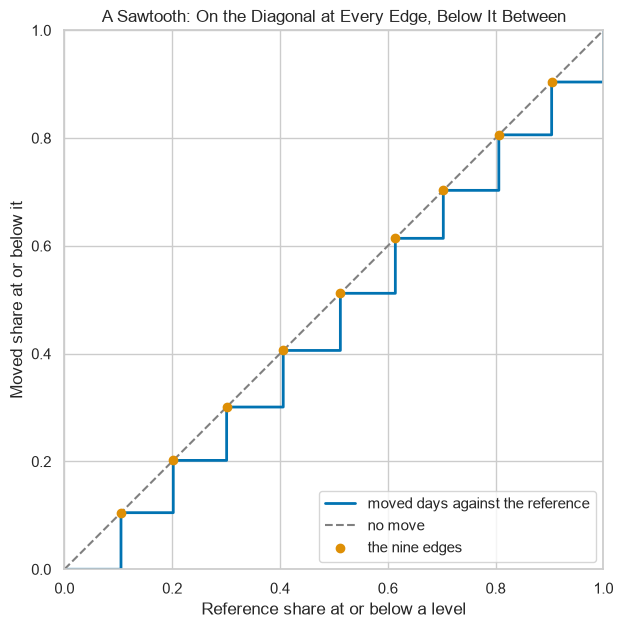

In [49]:
# the moved days' P-P plot: the curve against the diagonal, the nine edges marked
values = np.sort(np.concatenate([reference_level, moved]))
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cumulative_share(reference_level, values), cumulative_share(moved, values), drawstyle="steps-post", linewidth=2, label="moved days against the reference")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no move")
ax.scatter(cumulative_share(reference_level, level_edges), cumulative_share(moved, level_edges), color="C1", zorder=3, label="the nine edges")
ax.set_aspect("equal")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Reference share at or below a level", ylabel="Moved share at or below it", title="A Sawtooth: On the Diagonal at Every Edge, Below It Between")
ax.legend(loc="lower right")
plt.show()

PSI and Jensen-Shannon read exactly 0: every day stayed in its bin, so every share agreed.

KS saw the move as a gap of 0.099 between edges, where the curve sags below the diagonal and then touches it again.

## Shuffling Two Inputs Together

`rng.permutation` (Course 4's Day 3) reorders the reference firms' coverage, so each firm takes another firm's coverage: each column keeps its values, and the pairing breaks.

In [50]:
# a second experiment: the reference firms with their coverage shuffled
rng = np.random.default_rng(SEED)
shuffled = reference_firms.copy()
shuffled["coverage"] = rng.permutation(reference_firms["coverage"].to_numpy())
print("PSI leverage:", psi(reference_firms["leverage"], shuffled["leverage"], cohort_edges["leverage"]), "| PSI coverage:", psi(reference_firms["coverage"], shuffled["coverage"], cohort_edges["coverage"]))
print(f"Correlation of leverage and coverage: reference {reference_firms['leverage'].corr(reference_firms['coverage']):.3f} | shuffled {shuffled['leverage'].corr(shuffled['coverage']):.3f} | compared {compared_firms['leverage'].corr(compared_firms['coverage']):.3f}")

PSI leverage: 0.0 | PSI coverage: 0.0
Correlation of leverage and coverage: reference -0.587 | shuffled 0.003 | compared -0.609


A two-sample density contour draws each sample's density as rings that hold the same share of that sample.
In `sns.kdeplot`, `levels=[0.25, 0.5, 0.75]` draws the rings holding 75, 50 and 25 percent of each sample.
`common_norm=False` gives each group a density of its own, so 2,508 and 996 firms are drawn at the same levels.
`log_scale=(False, True)` puts coverage alone on a log axis.

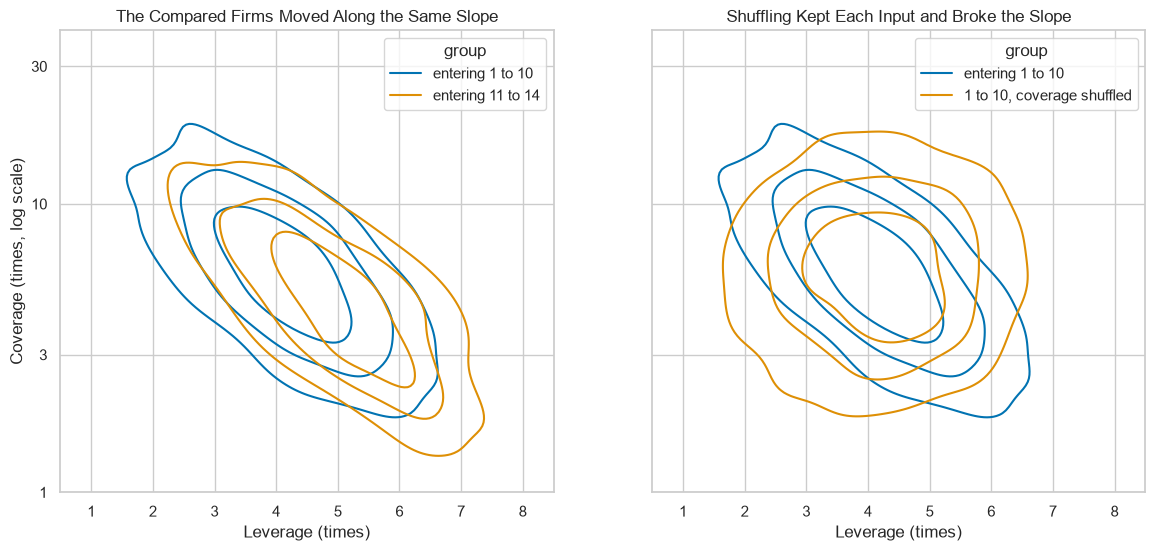

In [51]:
# each sample's contours holding 75, 50 and 25 percent of it, coverage on a log axis
groups = pd.concat([reference_firms.assign(group="entering 1 to 10"), compared_firms.assign(group="entering 11 to 14"), shuffled.assign(group="1 to 10, coverage shuffled")])
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, pair in zip(axes, [["entering 1 to 10", "entering 11 to 14"], ["entering 1 to 10", "1 to 10, coverage shuffled"]]):
    sns.kdeplot(data=groups[groups["group"].isin(pair)], x="leverage", y="coverage", hue="group", hue_order=pair, common_norm=False, fill=False, levels=[0.25, 0.5, 0.75], log_scale=(False, True), ax=ax)
    ax.set(xlim=(0.5, 8.5), ylim=(1, 40), yticks=[1, 3, 10, 30], yticklabels=["1", "3", "10", "30"], xlabel="Leverage (times)", ylabel="Coverage (times, log scale)")
axes[0].set_title("The Compared Firms Moved Along the Same Slope")
axes[1].set_title("Shuffling Kept Each Input and Broke the Slope")
plt.show()

The shuffle left both inputs' PSI at 0 and took the correlation from -0.587 to about 0.

The compared firms kept the reference's slope and moved along it.

**All three read one input at a time, so a broken pairing passes them all; a move inside the bins passes PSI and Jensen-Shannon.**

# Insights and Conclusion

The reference and its edges came first, before any compared value was read.

The 10 Yr level's PSI was 1.72 against its daily change's 0.041.

Past an empty bin the floor set the size, and more bins found more difference.

Quarters inside the reference read up to 0.39 on the change: a short window has its own noise.

The planted tilt showed in all three inputs of the entering firms, leverage as a block and coverage in proportion.

The KS p-value ranked evidence, not size; KS and Jensen-Shannon stopped near 1 where PSI followed the floor.

PSI read 0 for days moved inside their bins and for a broken pairing of two inputs.

**A PSI is a distance from one fixed reference on fixed bins: read it beside its own noise.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fix a reference sample and its quantile edges before reading the compared sample.
* Compute PSI by hand and with three small functions, and floor an empty bin.
* Turn the number of bins and the binning method, and count the bins actually used.
* Read PSI window by window against one reference, beside the reference's own windows.
* Measure each input's drift and draw where in the distribution it sits.
* Set PSI beside the KS test and Jensen-Shannon, and read the three side by side.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [52]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The 2 Yr Level**

Q. With the lesson's functions, store the PSI of the 2 Yr level in 2019 to 2022 against 2015 to 2018, on ten quantile bins of the reference, in `ex1_psi`.

In [53]:
# the 2 Yr level, split at the end of 2018, on ten quantile bins of its reference
two_year = curve.loc[:CUT, "2 Yr"]
reference_two, compared_two = two_year.loc[:"2018-12-31"], two_year.loc["2019-01-01":]
ex1_psi = psi(reference_two, compared_two, quantile_edges(reference_two))
print(f"2 Yr level PSI: {ex1_psi:.4f} | the 10 Yr level's: {level_psi:.4f}")

2 Yr level PSI: 1.5968 | the 10 Yr level's: 1.7173


The 2 Yr level also sat far from its reference's bins.

In [54]:
check("Exercise 1 the 2 Yr level's PSI", ex1_psi, 1.5967635907338118)

Exercise 1 the 2 Yr level's PSI: correct


### Exercise 2

**A PSI of Categories**

A column of categories, such as `sector`, needs no edges: each category seen in either sample is a bin.

Q. Write `psi_categories(reference, compared, floor=0.0001)`, which returns that PSI: each sample's `value_counts(normalize=True)`, `.reindex(categories, fill_value=0)` (Course 1) over `pd.concat([reference, compared]).unique()`, then the floor and the sum. Store the PSI of the entering firms' `sector`, 11 to 14 against 1 to 10, in `ex2_sector`.

In [55]:
def psi_categories(reference, compared, floor=0.0001):
    """PSI of a column of categories: one bin per category seen in either sample."""
    categories = pd.concat([reference, compared]).unique()
    reference_share = reference.value_counts(normalize=True).reindex(categories, fill_value=0).clip(lower=floor)
    compared_share = compared.value_counts(normalize=True).reindex(categories, fill_value=0).clip(lower=floor)
    return ((compared_share - reference_share) * np.log(compared_share / reference_share)).sum()

# the entering firms' sector, 11 to 14 against 1 to 10
ex2_sector = psi_categories(reference_firms["sector"], compared_firms["sector"])
print(f"Sector PSI: {ex2_sector:.4f} across {entrants['sector'].nunique()} sectors")

Sector PSI: 0.0090 across 10 sectors


The generator tilted ratings and leverage, not sectors, and the sector mix barely moved.

In [56]:
check("Exercise 2 the entering firms' sector PSI", ex2_sector, 0.00900104374572795)

Exercise 2 the entering firms' sector PSI: correct


### Exercise 3

**The 2 Yr's Change, Quarter by Quarter**

Q. Build the 2 Yr's daily change in whole bp as the lesson built the 10 Yr's, cut ten quantile bins on 2015 to 2018, and count the bins used. Then read every quarter's PSI against that reference, and store in `ex3_quarters` the number of quarters of 2019 to 2022 above the largest quarter inside the reference.

In [57]:
# the 2 Yr's daily change in whole bp, its reference edges, and the bins used
two_change = (two_year.diff() * 100).round(0).iloc[1:]
reference_two_change = two_change.loc[:"2018-12-31"]
two_edges = quantile_edges(reference_two_change)
print("Bins used:", len(two_edges) + 1, "of 10 asked")

# each quarter's PSI against that reference, and the quarters of 2019 to 2022 above the largest inside it
two_quarterly = {}
for label, days in two_change.groupby(two_change.index.to_period("Q")):
    two_quarterly[label] = psi(reference_two_change, days, two_edges)
two_quarterly = pd.Series(two_quarterly)
largest_inside = two_quarterly.loc[:"2018Q4"].max()
ex3_quarters = int((two_quarterly.loc["2019Q1":] > largest_inside).sum())
print(f"Largest inside: {largest_inside:.3f} ({two_quarterly.loc[:'2018Q4'].idxmax()}) | quarters of 2019 to 2022 above it: {ex3_quarters} of 16, against the 10 Yr's 4")

Bins used: 8 of 10 asked
Largest inside: 0.298 (2016Q1) | quarters of 2019 to 2022 above it: 13 of 16, against the 10 Yr's 4


The 2 Yr's small daily moves fill fewer whole-bp bins, and many more of its later quarters left the reference's own range of PSI.

In [58]:
check("Exercise 3 the 2 Yr's quarters above the reference's largest", ex3_quarters, 13)

Exercise 3 the 2 Yr's quarters above the reference's largest: correct


### Exercise 4: AI check

**A Stability Index**

You asked an AI assistant for a PSI function.
This came back.
Test it against the hand case in its docstring, then find the one bug.

In [59]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def stability_index(expected, actual, floor=0.0001):
    """PSI of actual against expected, on ten bins cut at expected's deciles. Expected 1 to 100 against actual 1 to 50 gives 3.7970."""
    edges = np.unique(np.quantile(actual, np.arange(1, 10) / 10))
    cuts = np.concatenate([[-np.inf], edges, [np.inf]])
    expected_share = pd.cut(expected, cuts).value_counts(normalize=True, sort=False).clip(lower=floor)
    actual_share = pd.cut(actual, cuts).value_counts(normalize=True, sort=False).clip(lower=floor)
    return ((actual_share - expected_share) * np.log(actual_share / expected_share)).sum()

In [60]:
# the docstring's hand case: five bins of 0.2 against 0.1, five empty bins floored
hand = 5 * (0.2 - 0.1) * np.log(0.2 / 0.1) + 5 * (0.0001 - 0.1) * np.log(0.0001 / 0.1)
print("By hand:", round(hand, 4), "| stability_index:", round(stability_index(pd.Series(np.arange(1.0, 101.0)), pd.Series(np.arange(1.0, 51.0))), 4))

By hand: 3.797 | stability_index: 1.0791


Q. Fix the one wrong line, check the hand case again, and store the fixed function's PSI of the 10 Yr level, 2019 to 2022 against 2015 to 2018, in `ex4_psi`.

In [61]:
# the fix: the deciles are cut on expected, the reference, never on the sample being checked
def stability_index(expected, actual, floor=0.0001):
    """PSI of actual against expected, on ten bins cut at expected's deciles. Expected 1 to 100 against actual 1 to 50 gives 3.7970."""
    edges = np.unique(np.quantile(expected, np.arange(1, 10) / 10))
    cuts = np.concatenate([[-np.inf], edges, [np.inf]])
    expected_share = pd.cut(expected, cuts).value_counts(normalize=True, sort=False).clip(lower=floor)
    actual_share = pd.cut(actual, cuts).value_counts(normalize=True, sort=False).clip(lower=floor)
    return ((actual_share - expected_share) * np.log(actual_share / expected_share)).sum()

print("Hand case:", round(stability_index(pd.Series(np.arange(1.0, 101.0)), pd.Series(np.arange(1.0, 51.0))), 4))
ex4_psi = stability_index(reference_level, compared_level)
print("10 Yr level:", ex4_psi, "| the lesson's psi:", level_psi)

Hand case: 3.797
10 Yr level: 1.7173293118420834 | the lesson's psi: 1.7173293118420834


Cut on `actual`, every bin held a tenth of the compared sample, so the bins moved with the very sample they should judge, and the hand case came out far too low.

Cut on `expected`, the hand case gives 3.7970 and the 10 Yr level the lesson's PSI to the last digit.

In [62]:
check("Exercise 4 the fixed function on the 10 Yr level", ex4_psi, 1.7173293118420834)

Exercise 4 the fixed function on the 10 Yr level: correct


## Congratulations!

You fixed a reference before reading anything else, and built PSI from its shares, its terms and its sum.
You found the 10 Yr's level far from its reference while its daily change kept its shape, and saw a floor, a bin count and a short window each set the number's size.
On the cohort you found the planted tilt in every input, and drew where in each distribution it sat.
Then you made two moves that PSI, KS and Jensen-Shannon read as small or as nothing, so you know what each one cannot see.
In Day 9 these functions watch a hazard model's inputs year by year, beside its ranking and its default counts.

[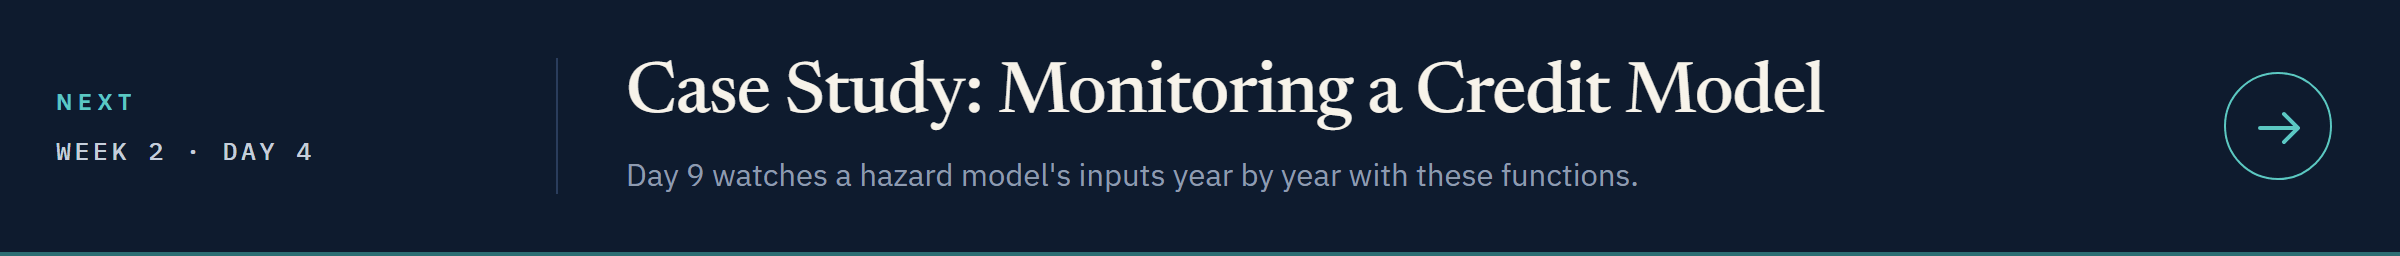](../day4/09_case_study_monitoring_a_credit_model.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day4/09_case_study_monitoring_a_credit_model.ipynb)